# 07. Seq2Seq 와 Attention

**Seq2Seq (Encoder–Decoder)**: 입력 시퀀스를 읽어서 다른 시퀀스를 만든다 (번역, 요약 등).

- Encoder RNN이 입력을 다 읽고 마지막 은닉 상태 $h$를 넘긴다.
- Decoder RNN은 $h$에서 출발해 출력을 한 토큰씩 생성한다.

**문제**: 입력 정보가 전부 $h$ 하나에 압축된다 (병목).
**Attention**: Decoder가 매 시점 **Encoder의 모든 시점 출력을 다시 보고**, 지금 필요한 위치에 가중치를 둔다.

실험 과제: **숫자 시퀀스 뒤집기** `3 1 4 1 5 → 5 1 4 1 3`. 출력의 첫 글자가 입력의 마지막 글자이므로, 입력 전체를 기억해야 한다.

> ⏱ CPU 기준 학습 셀 두 개가 각각 약 1.5~2.5분 걸립니다.

In [1]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
SOS = 10                 # 디코더 시작 토큰 (숫자 0~9 다음 번호)
VOCAB = 11               # 0~9 + SOS
SEQ_LEN = 16

def make_batch(batch_size, seq_len=SEQ_LEN):
    src = torch.randint(0, 10, (batch_size, seq_len))
    return src, src.flip(dims=[1])

src, tgt = make_batch(2, 8)
print("src:", src.tolist())
print("tgt:", tgt.tolist())

src: [[4, 9, 3, 0, 3, 9, 7, 3], [7, 3, 1, 6, 6, 9, 8, 6]]
tgt: [[3, 7, 9, 3, 0, 3, 9, 4], [6, 8, 9, 6, 6, 1, 3, 7]]


## 1. Encoder / Decoder

**Teacher forcing**: 학습할 때는 Decoder 입력으로 *자기가 예측한 것*이 아니라 **정답을 한 칸 밀어서** 넣는다.

```
Decoder 입력 : [SOS, t1, t2, ..., t_{n-1}]
Decoder 정답 : [t1,  t2, t3, ..., t_n]
```

이렇게 하면 학습이 안정적이고, 전체 시점을 한 번에 계산할 수 있다. 생성할 때는 한 토큰씩 자기 출력을 다시 넣는다.

In [2]:
class Encoder(nn.Module):
    def __init__(self, vocab, emb_dim, hidden):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb_dim)
        self.gru = nn.GRU(emb_dim, hidden, batch_first=True)

    def forward(self, src):                         # (B, S)
        enc_out, h = self.gru(self.emb(src))        # (B, S, H), (1, B, H)
        return enc_out, h


class Decoder(nn.Module):
    # Attention 없음: 인코더 정보는 초기 은닉 상태 h 로만 전달됨
    def __init__(self, vocab, emb_dim, hidden):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb_dim)
        self.gru = nn.GRU(emb_dim, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 10)

    def forward(self, dec_in, h, enc_out):          # enc_out은 쓰지 않음
        dec_out, h = self.gru(self.emb(dec_in), h)  # (B, T, H)
        return self.head(dec_out), h, None


class Seq2Seq(nn.Module):
    def __init__(self, decoder_cls, emb_dim=32, hidden=128):
        super().__init__()
        self.encoder = Encoder(VOCAB, emb_dim, hidden)
        self.decoder = decoder_cls(VOCAB, emb_dim, hidden)

    def forward(self, src, tgt):                    # 학습: teacher forcing
        enc_out, h = self.encoder(src)
        dec_in = torch.cat([torch.full_like(tgt[:, :1], SOS), tgt[:, :-1]], dim=1)
        logits, _, attn = self.decoder(dec_in, h, enc_out)
        return logits, attn

    @torch.no_grad()
    def generate(self, src):                        # 추론: 한 토큰씩
        enc_out, h = self.encoder(src)
        tok = torch.full((src.size(0), 1), SOS)
        outs, attns = [], []
        for _ in range(src.size(1)):
            logits, h, w = self.decoder(tok, h, enc_out)
            tok = logits.argmax(dim=-1)             # (B, 1)
            outs.append(tok)
            attns.append(w)
        attn = torch.cat(attns, dim=1) if attns[0] is not None else None
        return torch.cat(outs, dim=1), attn

In [3]:
def train_seq2seq(model, steps=1500, batch_size=128):
    optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
    start = time.time()
    for step in range(steps):
        src, tgt = make_batch(batch_size)
        logits, _ = model(src, tgt)
        loss = F.cross_entropy(logits.reshape(-1, 10), tgt.reshape(-1))
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        if step % 300 == 0 or step == steps - 1:
            print(f"  step {step:4d}  loss {loss.item():.3f}")
    print(f"  ({time.time() - start:.0f}s)")


def accuracy(model, n=1000):
    model.eval()
    src, tgt = make_batch(n)
    pred, _ = model.generate(src)
    tok_acc = (pred == tgt).float().mean().item()
    seq_acc = (pred == tgt).all(dim=1).float().mean().item()
    return tok_acc, seq_acc


torch.manual_seed(0)
plain = Seq2Seq(Decoder)
train_seq2seq(plain)
print("Attention 없음 → 토큰 정확도 %.3f, 문장 전체 정확도 %.3f" % accuracy(plain))

  step    0  loss 2.303


  step  300  loss 0.886


  step  600  loss 0.594


  step  900  loss 0.334


  step 1200  loss 0.232


  step 1499  loss 0.156
  (97s)
Attention 없음 → 토큰 정확도 0.855, 문장 전체 정확도 0.388


## 2. Attention Decoder (Luong 방식, dot-product)

Decoder의 각 시점 은닉 상태 $s_t$ 를 **Query**, Encoder 출력 $h_1..h_S$ 를 **Key**이자 **Value**로 쓴다.

1. 점수: $e_{t,i} = s_t \cdot h_i$ → `dec_out @ enc_out.transpose(1, 2)` : `(B, T, S)`
2. 가중치: $\alpha_{t} = \text{softmax}(e_t)$ (입력 위치에 대한 확률분포)
3. 문맥 벡터: $c_t = \sum_i \alpha_{t,i} h_i$ → `weights @ enc_out` : `(B, T, H)`
4. $[s_t; c_t]$ 를 이어 붙여 출력을 예측

In [4]:
class AttnDecoder(nn.Module):
    def __init__(self, vocab, emb_dim, hidden):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb_dim)
        self.gru = nn.GRU(emb_dim, hidden, batch_first=True)
        self.combine = nn.Linear(2 * hidden, hidden)
        self.head = nn.Linear(hidden, 10)

    def forward(self, dec_in, h, enc_out):
        dec_out, h = self.gru(self.emb(dec_in), h)          # (B, T, H)  ← Query
        scores = dec_out @ enc_out.transpose(1, 2)           # (B, T, S)
        weights = torch.softmax(scores, dim=-1)              # 입력 위치별 가중치
        context = weights @ enc_out                          # (B, T, H)
        out = torch.tanh(self.combine(torch.cat([dec_out, context], dim=-1)))
        return self.head(out), h, weights


torch.manual_seed(0)
attn_model = Seq2Seq(AttnDecoder)
train_seq2seq(attn_model)
print("Attention 사용 → 토큰 정확도 %.3f, 문장 전체 정확도 %.3f" % accuracy(attn_model))

  step    0  loss 2.304


  step  300  loss 0.004


  step  600  loss 0.006


  step  900  loss 0.004


  step 1200  loss 0.000


  step 1499  loss 0.000
  (136s)


Attention 사용 → 토큰 정확도 0.996, 문장 전체 정확도 0.985


## 3. Attention 가중치 시각화

출력 $t$번째(세로)가 입력의 어느 위치(가로)를 보았는지 나타낸다. 뒤집기 과제이므로 **반대 대각선**이 나타나야 한다.
모델이 "출력 1번째 = 입력 마지막"이라는 대응 관계를 스스로 학습한 것이다.

src : [6, 8, 2, 8, 3, 8, 3, 0, 0, 1, 9, 2, 9, 9, 1, 2]
pred: [2, 1, 9, 9, 2, 9, 1, 0, 0, 3, 8, 3, 8, 2, 8, 6]
tgt : [2, 1, 9, 9, 2, 9, 1, 0, 0, 3, 8, 3, 8, 2, 8, 6]


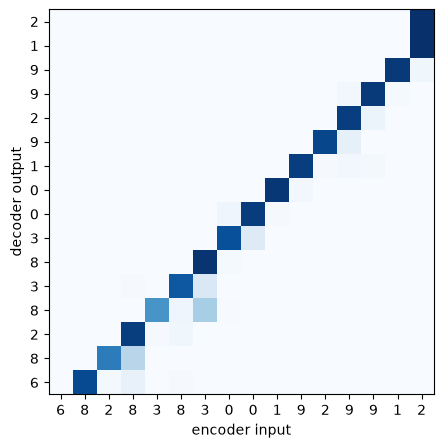

In [5]:
src, tgt = make_batch(1)
pred, attn = attn_model.generate(src)
print("src :", src[0].tolist())
print("pred:", pred[0].tolist())
print("tgt :", tgt[0].tolist())

plt.figure(figsize=(5, 5))
plt.imshow(attn[0], cmap="Blues")
plt.xticks(range(SEQ_LEN), src[0].tolist())
plt.yticks(range(SEQ_LEN), pred[0].tolist())
plt.xlabel("encoder input")
plt.ylabel("decoder output")
plt.show()

## 정리 → 다음 노트북

- Attention = **Query**가 여러 **Key**와 유사도를 계산하고, 그 가중치로 **Value**를 섞는 연산
- 여기서는 Query = Decoder 상태, Key = Value = Encoder 출력 (Cross-Attention)
- **Self-Attention**: Query/Key/Value를 모두 **같은 시퀀스**에서 만든다. RNN 없이 각 토큰이 다른 모든 토큰을 바로 볼 수 있다. 이것이 Transformer의 핵심이다 (08).